In [2]:
%load_ext autoreload
%autoreload 2

In [45]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED, is_higher_better, get_metric_abbr, get_metric_label

In [4]:
dataset = build_dataset('test')

In [5]:
unet_baseline = ModelResults('147-deeplabv3plus-l2', 'unet', 199, 'test', dataset)

In [20]:
baseline_results = []

for seed in range(1, 11):
  sampling_name = f'ddpm-seed{seed}-1000' if seed > 1 else 'ddpm-1000'
  baseline_results.append(ModelResults('212-beamdiff-mp', sampling_name, 199, 'test', dataset))
  baseline_results.append(ModelResults('227-beamdiff-2', sampling_name, 199, 'test', dataset))
  baseline_results.append(ModelResults('228-beamdiff-3', sampling_name, 199, 'test', dataset))
  baseline_results.append(ModelResults('229-beamdiff-4', sampling_name, 199, 'test', dataset))
  baseline_results.append(ModelResults('230-beamdiff-5', sampling_name, 199, 'test', dataset))

baseline_comparison = ModelComparison(baseline_results, ['Model 1'] * 10 + ['Model 2'] * 10 + ['Model 3'] * 10 + ['Model 4'] * 10 + ['Model 5'] * 10, ['DDPM'] * 50)

In [ ]:
baseline = ModelResults('212-beamdiff-mp', 'ddpm-1000', 199, 'test', dataset)

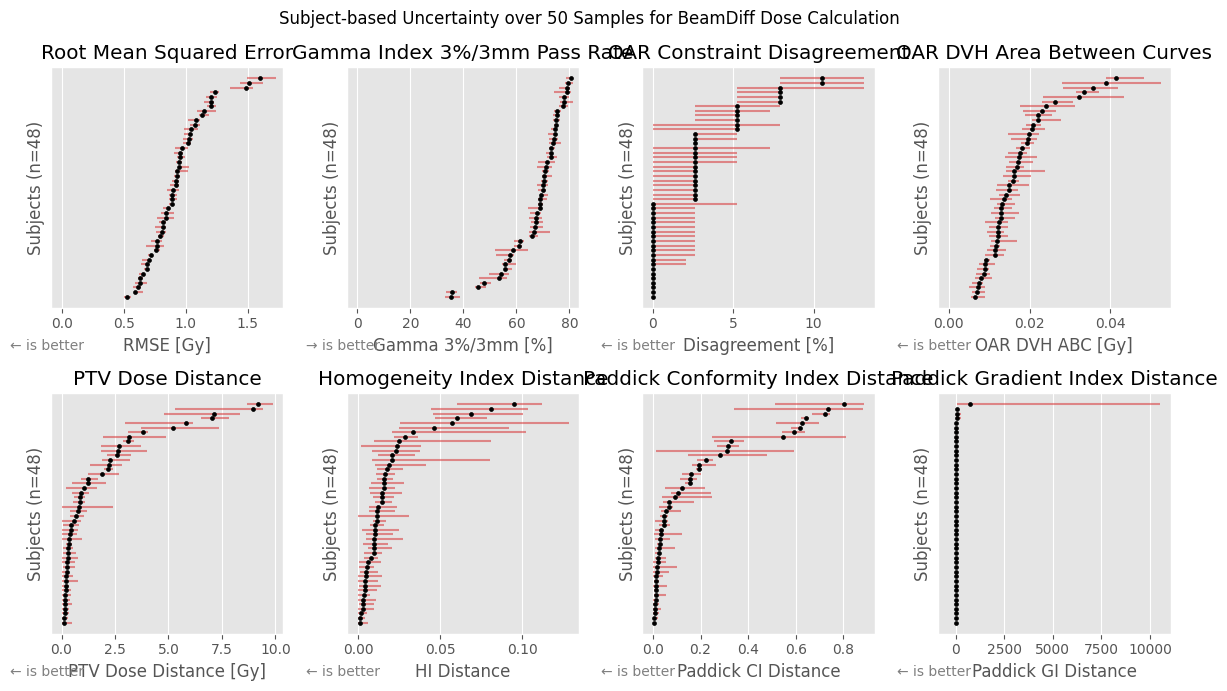

In [47]:
# Build a long-form DataFrame with all runs pooled, keyed by subject
rows = []
for result in baseline_comparison.results_list:
  for _, row in result.volume_metrics.iterrows():
    rows.append(row)

all_volumes = pd.DataFrame(rows)

# Per-subject statistics for each metric
per_subject = {}
for metric in METRICS_PLAN_EXTENDED:
  grouped = all_volumes.groupby('file_name')[metric]
  per_subject[metric] = pd.DataFrame({
    'median': grouped.median(),
    'iqr': grouped.quantile(0.75) - grouped.quantile(0.25),
    'range': grouped.max() - grouped.min(),
    'q025': grouped.quantile(0.025),
    'q975': grouped.quantile(0.975),
    'width': grouped.quantile(0.975) - grouped.quantile(0.025),
    'max': grouped.max(),
  })

fig, axes = plt.subplots(2, 4, figsize=(12, 7))
axes = axes.flatten()

for i, metric in enumerate(METRICS_PLAN_EXTENDED):
  stats = per_subject[metric].sort_values(['median', 'q025', 'q975'])
  label = get_metric_label(metric)
  abbr = get_metric_abbr(metric)
  ax = axes[i]

  # Plot each subject as a horizontal bar from q025 to q975, with median dot
  y = np.arange(len(stats))
  ax.hlines(y, stats['q025'], stats['q975'], color='tab:red', alpha=0.5, linewidth=1.5)
  ax.scatter(stats['median'], y, color='black', s=8, zorder=3)

  dir_symbol = '→' if is_higher_better(metric) else '←'
  ax.set_title(f'{label}')
  ax.set_xlabel(abbr)
  ax.set_ylabel('Subjects (n=48)')
  ax.set_yticks([])
  ax.set_xlim(-0.05 * stats['max'].max())
  ax.text(0.18, -0.132, f'{dir_symbol} is better  ', transform=ax.transAxes,
    ha='right', va='top', fontsize='medium', color='gray')

fig.suptitle('Subject-based Uncertainty over 50 Samples for BeamDiff Dose Calculation')
fig.tight_layout()
plt.show()

## Quantization

In [40]:
baseline_fp32 = ModelResults('201-beamdiff', 'ddpm-1000', 199, 'test', dataset)

In [41]:
train_quant_comparison = ModelComparison(
  [baseline_fp32, baseline],
  ['FP32', 'BF16'],
  ['DDPM', 'DDPM']
)

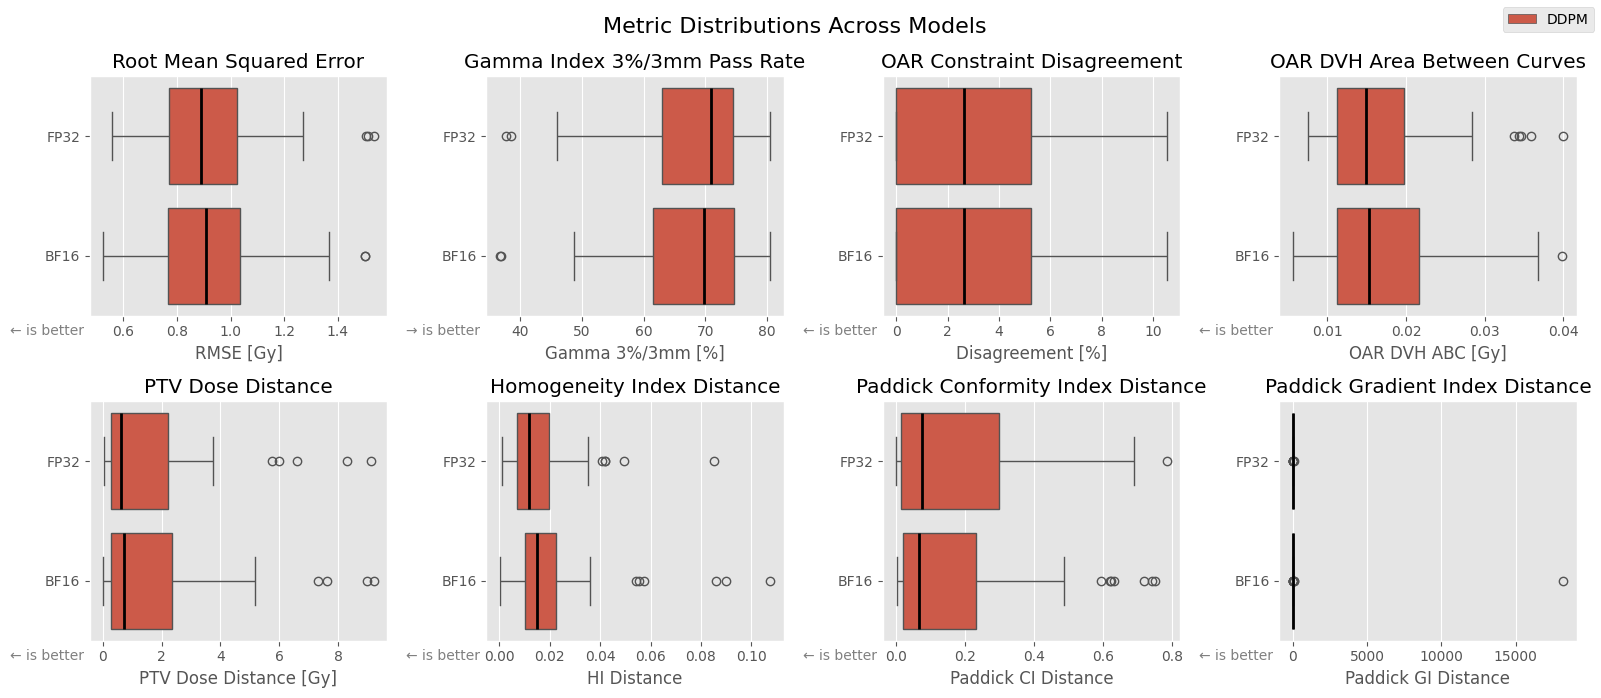

In [42]:
_ = train_quant_comparison.plot_metric_distributions(METRICS_PLAN_EXTENDED)

In [43]:
baseline_samp_bf16 = ModelResults('212-beamdiff-mp', 'ddpm-1000-bf16-amp', 199, 'test', dataset)

In [48]:
sample_quant_comparison = ModelComparison(
  [baseline_fp32, baseline_samp_bf16],
  ['FP32', 'BF16'],
  ['DDPM', 'DDPM']
)

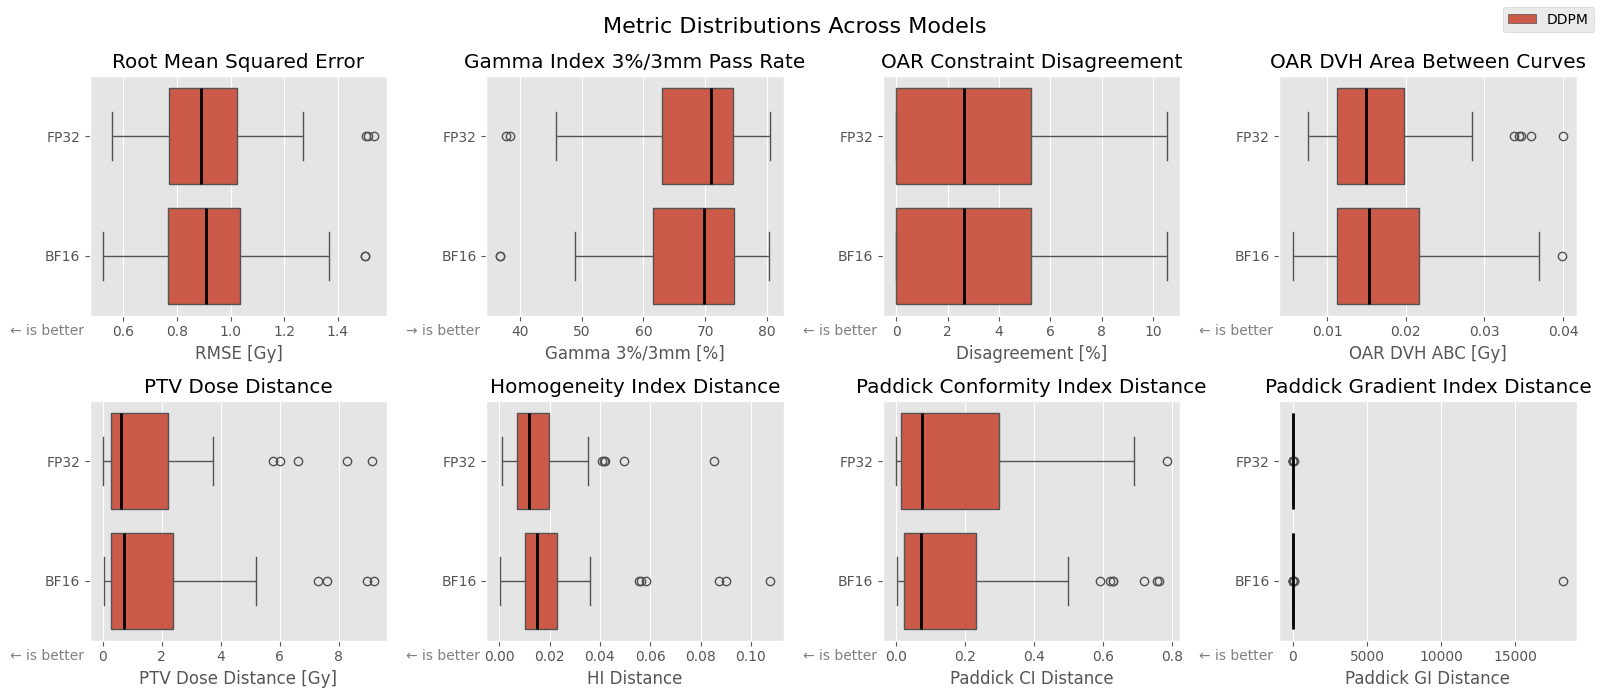

In [49]:
_ = sample_quant_comparison.plot_metric_distributions(METRICS_PLAN_EXTENDED)

## T

In [ ]:
ddpm_500 = ModelResults('212-beamdiff-mp', 'ddpm-500', 199, 'test', dataset)
ddpm_100 = ModelResults('212-beamdiff-mp', 'ddpm-100', 199, 'test', dataset)
ddpm_50 = ModelResults('212-beamdiff-mp', 'ddpm-50', 199, 'test', dataset)
ddpm_10 = ModelResults('212-beamdiff-mp', 'ddpm-10', 199, 'test', dataset)
ddpm_5 = ModelResults('212-beamdiff-mp', 'ddpm-5', 199, 'test', dataset)
ddpm_4 = ModelResults('212-beamdiff-mp', 'ddpm-4', 199, 'test', dataset)
ddpm_3 = ModelResults('212-beamdiff-mp', 'ddpm-3', 199, 'test', dataset)
ddpm_2 = ModelResults('212-beamdiff-mp', 'ddpm-2', 199, 'test', dataset)
ddpm_1 = ModelResults('212-beamdiff-mp', 'ddpm-1', 199, 'test', dataset)

ddim_1000 = ModelResults('212-beamdiff-mp', 'ddim-1000', 199, 'test', dataset)
ddim_500 = ModelResults('212-beamdiff-mp', 'ddim-500', 199, 'test', dataset)
ddim_100 = ModelResults('212-beamdiff-mp', 'ddim-100', 199, 'test', dataset)
ddim_50 = ModelResults('212-beamdiff-mp', 'ddim-50', 199, 'test', dataset)
ddim_10 = ModelResults('212-beamdiff-mp', 'ddim-10', 199, 'test', dataset)
ddim_5 = ModelResults('212-beamdiff-mp', 'ddim-5', 199, 'test', dataset)
ddim_4 = ModelResults('212-beamdiff-mp', 'ddim-4', 199, 'test', dataset)
ddim_3 = ModelResults('212-beamdiff-mp', 'ddim-3', 199, 'test', dataset)
ddim_2 = ModelResults('212-beamdiff-mp', 'ddim-2', 199, 'test', dataset)
ddim_1 = ModelResults('212-beamdiff-mp', 'ddim-1', 199, 'test', dataset)

deis_1_1000 = ModelResults('212-beamdiff-mp', 'deis-1-1000', 199, 'test', dataset)
deis_1_500 = ModelResults('212-beamdiff-mp', 'deis-1-500', 199, 'test', dataset)
deis_1_100 = ModelResults('212-beamdiff-mp', 'deis-1-100', 199, 'test', dataset)
deis_1_50 = ModelResults('212-beamdiff-mp', 'deis-1-50', 199, 'test', dataset)
deis_1_10 = ModelResults('212-beamdiff-mp', 'deis-1-10', 199, 'test', dataset)
deis_1_5 = ModelResults('212-beamdiff-mp', 'deis-1-5', 199, 'test', dataset)
deis_1_4 = ModelResults('212-beamdiff-mp', 'deis-1-4', 199, 'test', dataset)
deis_1_3 = ModelResults('212-beamdiff-mp', 'deis-1-3', 199, 'test', dataset)
deis_1_2 = ModelResults('212-beamdiff-mp', 'deis-1-2', 199, 'test', dataset)
deis_1_1 = ModelResults('212-beamdiff-mp', 'deis-1-1', 199, 'test', dataset)

deis_2_1000 = ModelResults('212-beamdiff-mp', 'deis-2-1000', 199, 'test', dataset)
deis_2_500 = ModelResults('212-beamdiff-mp', 'deis-2-500', 199, 'test', dataset)
deis_2_100 = ModelResults('212-beamdiff-mp', 'deis-2-100', 199, 'test', dataset)
deis_2_50 = ModelResults('212-beamdiff-mp', 'deis-2-50', 199, 'test', dataset)
deis_2_10 = ModelResults('212-beamdiff-mp', 'deis-2-10', 199, 'test', dataset)
deis_2_5 = ModelResults('212-beamdiff-mp', 'deis-2-5', 199, 'test', dataset)
deis_2_4 = ModelResults('212-beamdiff-mp', 'deis-2-4', 199, 'test', dataset)
deis_2_3 = ModelResults('212-beamdiff-mp', 'deis-2-3', 199, 'test', dataset)
deis_2_2 = ModelResults('212-beamdiff-mp', 'deis-2-2', 199, 'test', dataset)
deis_2_1 = ModelResults('212-beamdiff-mp', 'deis-2-1', 199, 'test', dataset)

deis_3_1000 = ModelResults('212-beamdiff-mp', 'deis-3-1000', 199, 'test', dataset)
deis_3_500 = ModelResults('212-beamdiff-mp', 'deis-3-500', 199, 'test', dataset)
deis_3_100 = ModelResults('212-beamdiff-mp', 'deis-3-100', 199, 'test', dataset)
deis_3_50 = ModelResults('212-beamdiff-mp', 'deis-3-50', 199, 'test', dataset)
deis_3_10 = ModelResults('212-beamdiff-mp', 'deis-3-10', 199, 'test', dataset)
deis_3_5 = ModelResults('212-beamdiff-mp', 'deis-3-5', 199, 'test', dataset)
deis_3_4 = ModelResults('212-beamdiff-mp', 'deis-3-4', 199, 'test', dataset)
deis_3_3 = ModelResults('212-beamdiff-mp', 'deis-3-3', 199, 'test', dataset)
deis_3_2 = ModelResults('212-beamdiff-mp', 'deis-3-2', 199, 'test', dataset)
deis_3_1 = ModelResults('212-beamdiff-mp', 'deis-3-1', 199, 'test', dataset)

In [28]:
beamdiff_ddpm_samp_plan_comparison = ModelComparison(
  [baseline, ddpm_500, ddpm_100, ddpm_50, ddpm_10, ddpm_5, ddpm_4, ddpm_3, ddpm_2, ddpm_1],
  ['S=1000', 'S=500', 'S=100', 'S=50', 'S=10', 'S=5', 'S=4', 'S=3', 'S=2', 'S=1'],
  ['DDPM'] * 10
)

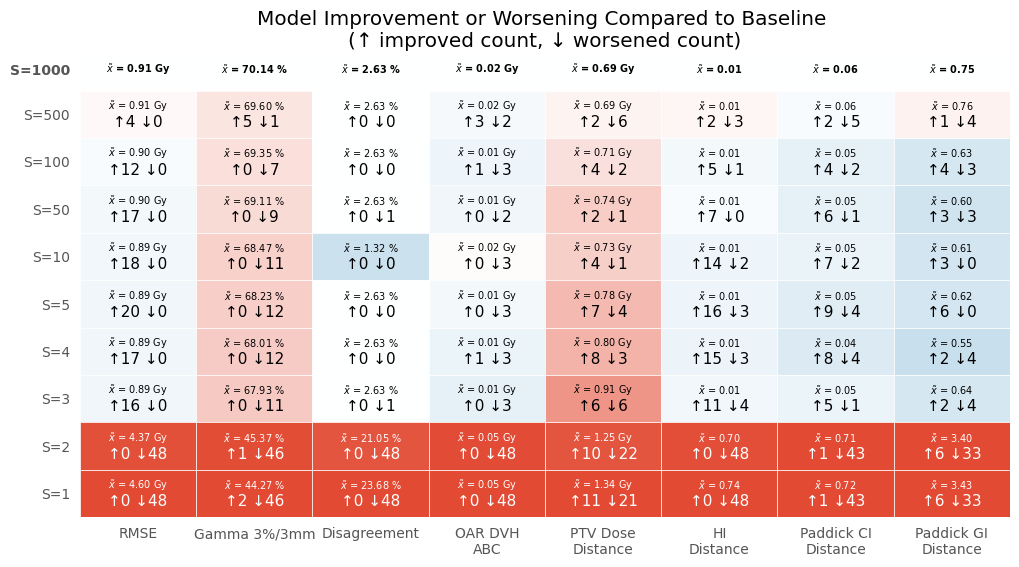

In [30]:
filtered_comparison = beamdiff_ddpm_samp_plan_comparison - baseline

fig, ax = plt.subplots(figsize=(12, 6))
_ = filtered_comparison.plot_metric_heatmap(
  METRICS_PLAN_EXTENDED,
  baseline=baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=False,
  baseline_label='S=1000',
  ax=ax
)

In [ ]:
sampler_comparison = ModelComparison(
  [baseline, ddpm_500, ddpm_100, ddpm_50, ddpm_10, ddpm_5, ddpm_4, ddpm_3, ddpm_2, ddpm_1,
   ddim_1000, ddim_500, ddim_100, ddim_50, ddim_10, ddim_5, ddim_4, ddim_3, ddim_2, ddim_1,
   deis_1_1000, deis_1_500, deis_1_100, deis_1_50, deis_1_10, deis_1_5, deis_1_4, deis_1_3, deis_1_2, deis_1_1,
   deis_2_1000, deis_2_500, deis_2_100, deis_2_50, deis_2_10, deis_2_5, deis_2_4, deis_2_3, deis_2_2, deis_2_1,
   deis_3_1000, deis_3_500, deis_3_100, deis_3_50, deis_3_10, deis_3_5, deis_3_4, deis_3_3, deis_3_2, deis_3_1],
  ['DDPM S=1000', 'DDPM S=500', 'DDPM S=100', 'DDPM S=50', 'DDPM S=10', 'DDPM S=5', 'DDPM S=4', 'DDPM S=3', 'DDPM S=2', 'DDPM S=1',
   'DDIM S=1000', 'DDIM S=500', 'DDIM S=100', 'DDIM S=50', 'DDIM S=10', 'DDIM S=5', 'DDIM S=4', 'DDIM S=3', 'DDIM S=2', 'DDIM S=1',
   'DEIS 1 S=1000', 'DEIS 1 S=500', 'DEIS 1 S=100', 'DEIS 1 S=50', 'DEIS 1 S=10', 'DEIS 1 S=5', 'DEIS 1 S=4', 'DEIS 1 S=3', 'DEIS 1 S=2', 'DEIS 1 S=1',
   'DEIS 2 S=1000', 'DEIS 2 S=500', 'DEIS 2 S=100', 'DEIS 2 S=50', 'DEIS 2 S=10', 'DEIS 2 S=5', 'DEIS 2 S=4', 'DEIS 2 S=3', 'DEIS 2 S=2', 'DEIS 2 S=1',
   'DEIS 3 S=1000', 'DEIS 3 S=500', 'DEIS 3 S=100', 'DEIS 3 S=50', 'DEIS 3 S=10', 'DEIS 3 S=5', 'DEIS 3 S=4', 'DEIS 3 S=3', 'DEIS 3 S=2', 'DEIS 3 S=1'],
  ['DDPM'] * 10 + ['DDIM'] * 10 + ['DEIS 1'] * 10 + ['DEIS 2'] * 10 + ['DEIS 3'] * 10
)

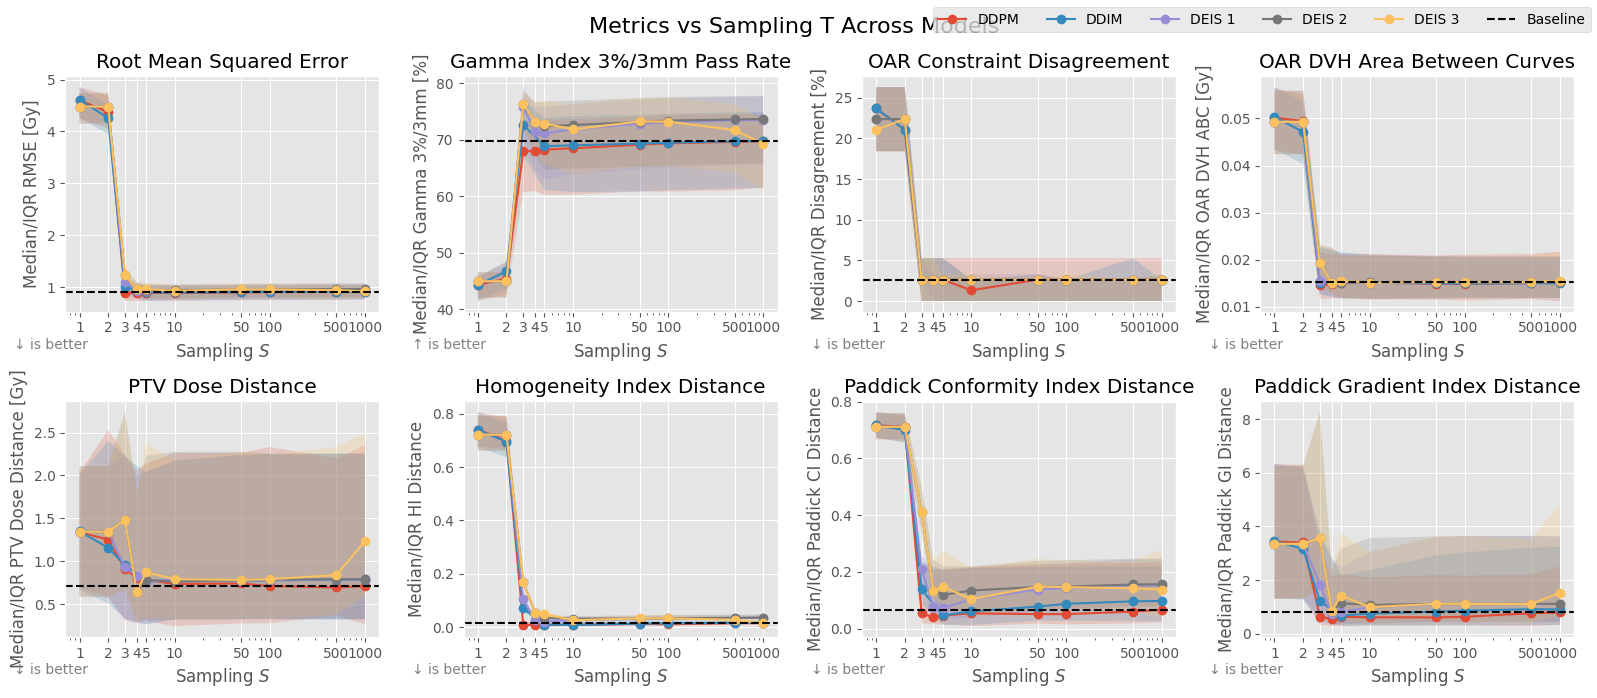

In [50]:
fig, axes = sampler_comparison.plot_quality_over_T(METRICS_PLAN_EXTENDED, baseline=baseline, agg='median', xscale='log')


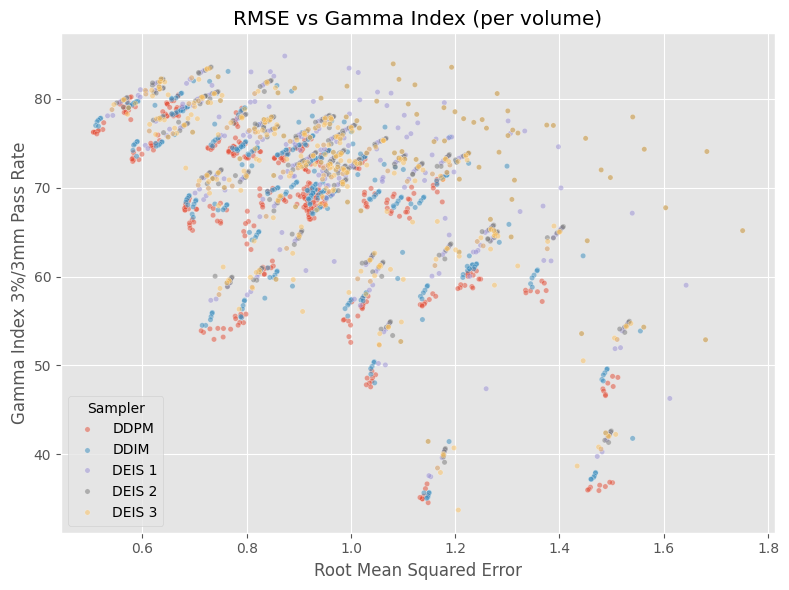

In [38]:
label_to_group = dict(zip(sampler_comparison.result_labels, sampler_comparison.result_groups))
df = sampler_comparison.volume_metrics.copy()
df['group'] = df['label'].map(label_to_group)
df = df[~df['label'].str.contains('S=1$|S=2$', regex=True)]

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df, x='vol_rmse', y='vol_gamma_3_3/pass_rate', hue='group', alpha=0.5, s=15, ax=ax)
ax.set_xlabel(get_metric_label('vol_rmse'))
ax.set_ylabel(get_metric_label('vol_gamma_3_3/pass_rate'))
ax.set_title('RMSE vs Gamma Index (per volume)')
ax.legend(title='Sampler')
plt.tight_layout()

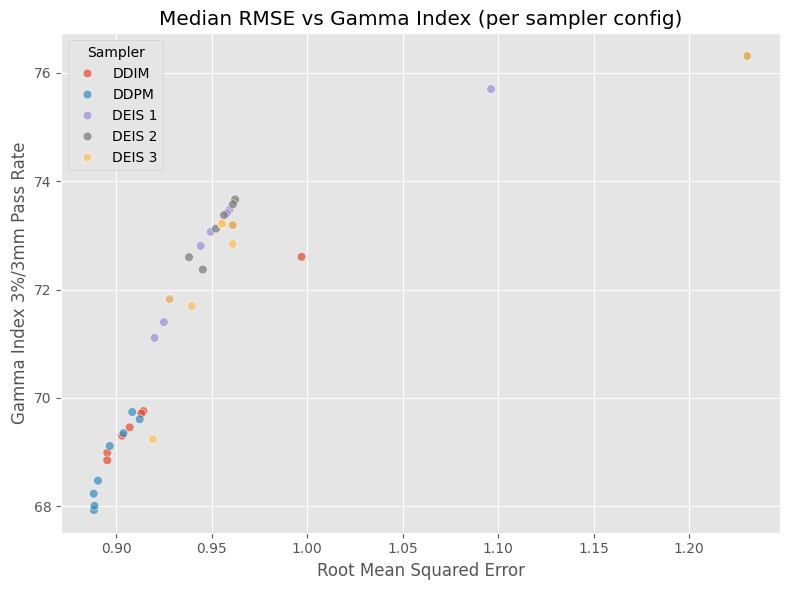

In [39]:
df_median = df.groupby(['label', 'group'])[['vol_rmse', 'vol_gamma_3_3/pass_rate']].median().reset_index()

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df_median, x='vol_rmse', y='vol_gamma_3_3/pass_rate', hue='group', alpha=0.7, s=40, ax=ax)
ax.set_xlabel(get_metric_label('vol_rmse'))
ax.set_ylabel(get_metric_label('vol_gamma_3_3/pass_rate'))
ax.set_title('Median RMSE vs Gamma Index (per sampler config)')
ax.legend(title='Sampler')
plt.tight_layout()

## Architecture

In [ ]:
merged_all = ModelResults('217-merged-all', 'ddpm-1000', 199, 'test', dataset)
merged_conditition = ModelResults('218-merged-condition', 'ddpm-1000', 199, 'test', dataset)
no_mam = ModelResults('219-no-mam', 'ddpm-1000', 199, 'test', dataset)
no_afm = ModelResults('220-no-afm', 'ddpm-1000', 199, 'test', dataset)
no_self_attn = ModelResults('221-no-self-attn', 'ddpm-1000', 199, 'test', dataset)
base_channels_64 = ModelResults('222-base-channels-64', 'ddpm-1000', 199, 'test', dataset)
res_blocks_1 = ModelResults('223-res-blocks-1', 'ddpm-1000', 199, 'test', dataset)
channels_1123 = ModelResults('224-channels-1123', 'ddpm-1000', 199, 'test', dataset)
channels_11123 = ModelResults('225-channels-11123', 'ddpm-1000', 199, 'test', dataset)
no_bottleneck_attn = ModelResults('240-no-bottleneck-attn', 'ddpm-1000', 199, 'test', dataset)
optimised_arch = ModelResults('226-optimised-arch', 'ddpm-1000', 199, 'test', dataset)
optimised_arch2 = ModelResults('241-optimised-arch-2', 'ddpm-1000', 199, 'test', dataset)

In [16]:
comparison = ModelComparison(
  [baseline, merged_all, merged_conditition, no_mam, no_afm, no_self_attn, base_channels_64, res_blocks_1, no_bottleneck_attn, channels_1123, channels_11123, optimised_arch, optimised_arch2],
  ['Baseline', 'Merged All', 'Merged Condition', 'No MAM', 'No AFM', 'No Self-Attn', 'Base Channels 64', 'Res Blocks 1', 'No Bottleneck Attn', 'Channels 1123', 'Channels 11123', 'Optimised Arch', 'Optimised Arch 2']
)

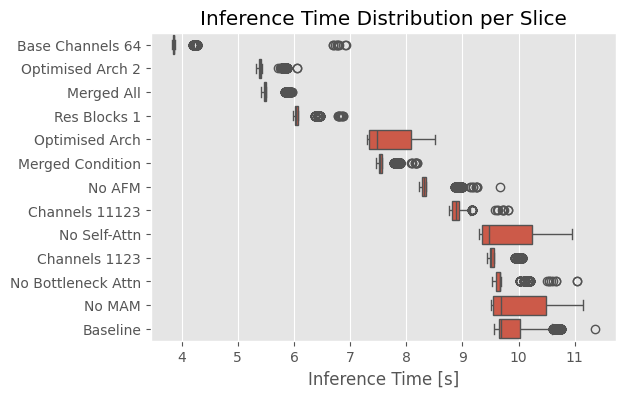

In [17]:
_ = comparison.plot_inference_times('slice', 'seconds')

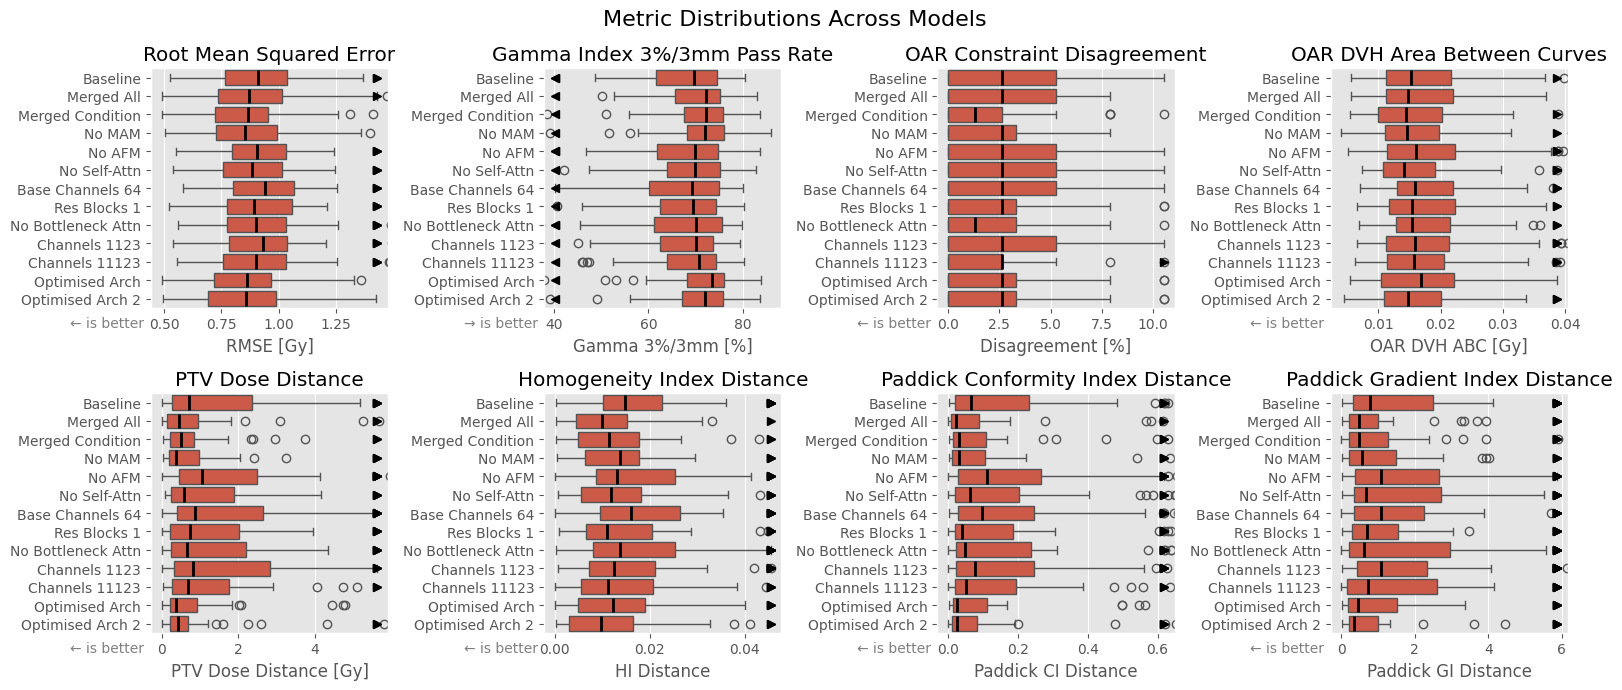

In [18]:
_ = comparison.plot_metric_distributions(METRICS_PLAN_EXTENDED, outliers=False)

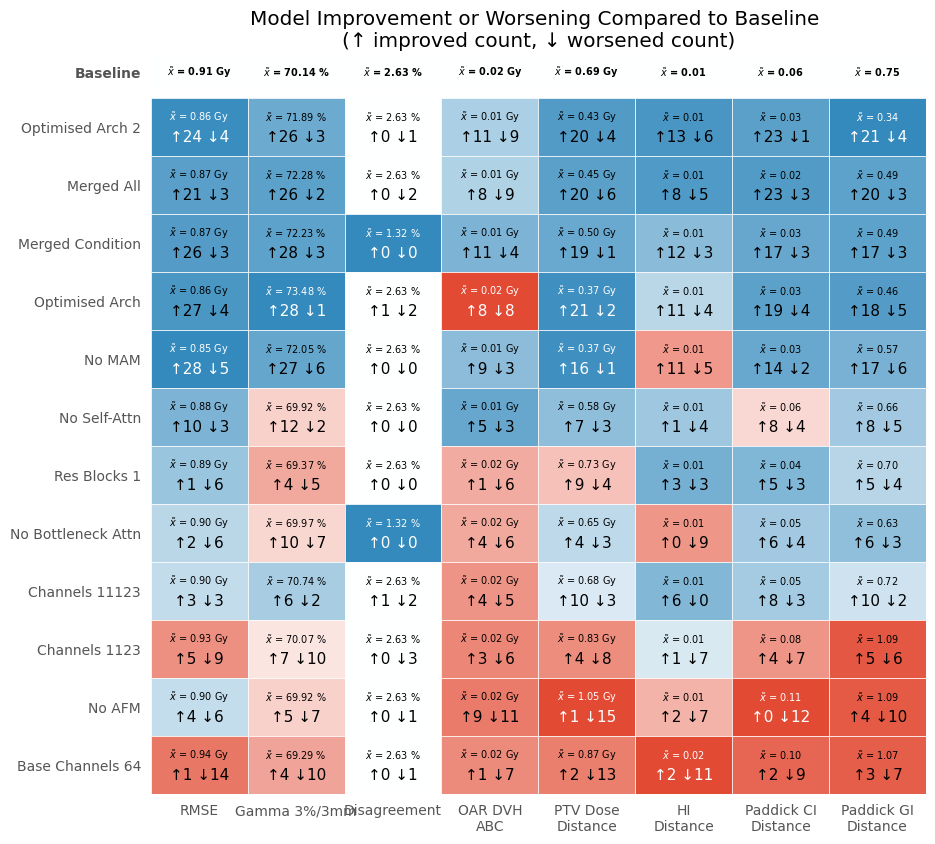

In [21]:
_ = (comparison - baseline).plot_metric_heatmap(
  METRICS_PLAN_EXTENDED,
  baseline=baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=True,
  baseline_label='Baseline',
)

## RFM

In [ ]:
# TODO 500, 1000
beamdiff_flow_100_plan = ModelResults('231-rfm', 'flow-100', 199, 'test', dataset)
beamdiff_flow_50_plan = ModelResults('231-rfm', 'flow-50', 199, 'test', dataset)
beamdiff_flow_10_plan = ModelResults('231-rfm', 'flow-10', 199, 'test', dataset)
beamdiff_flow_5_plan = ModelResults('231-rfm', 'flow-5', 199, 'test', dataset)
beamdiff_flow_4_plan = ModelResults('231-rfm', 'flow-4', 199, 'test', dataset)
beamdiff_flow_3_plan = ModelResults('231-rfm', 'flow-3', 199, 'test', dataset)
beamdiff_flow_2_plan = ModelResults('231-rfm', 'flow-2', 199, 'test', dataset)
beamdiff_flow_1_plan = ModelResults('231-rfm', 'flow-1', 199, 'test', dataset)

In [52]:
beamdiff_flow_comparison = ModelComparison(
  [beamdiff_flow_100_plan, beamdiff_flow_50_plan, beamdiff_flow_10_plan, beamdiff_flow_5_plan, beamdiff_flow_4_plan, beamdiff_flow_3_plan, beamdiff_flow_2_plan, beamdiff_flow_1_plan],
  ['S=100', 'S=50', 'S=10', 'S=5', 'S=4', 'S=3', 'S=2', 'S=1'],
  ['RFM'] * 8
)

In [55]:
beamdiff_ddpm_flow_plan_comparison = ModelComparison(
  [ddpm_100, ddpm_50, ddpm_10, ddpm_5, ddpm_4, ddpm_3, ddpm_2, ddpm_1,
   beamdiff_flow_100_plan, beamdiff_flow_50_plan, beamdiff_flow_10_plan, beamdiff_flow_5_plan, beamdiff_flow_4_plan, beamdiff_flow_3_plan, beamdiff_flow_2_plan, beamdiff_flow_1_plan],
  ['DDPM S=100', 'DDPM S=50', 'DDPM S=10', 'DDPM S=5', 'DDPM S=4', 'DDPM S=3', 'DDPM S=2', 'DDPM S=1',
   'RFM S=100', 'RFM S=50', 'RFM S=10', 'RFM S=5', 'RFM S=4', 'RFM S=3', 'RFM S=2', 'RFM S=1'],
  ['DDPM'] * 8 + ['Flow'] * 8
)

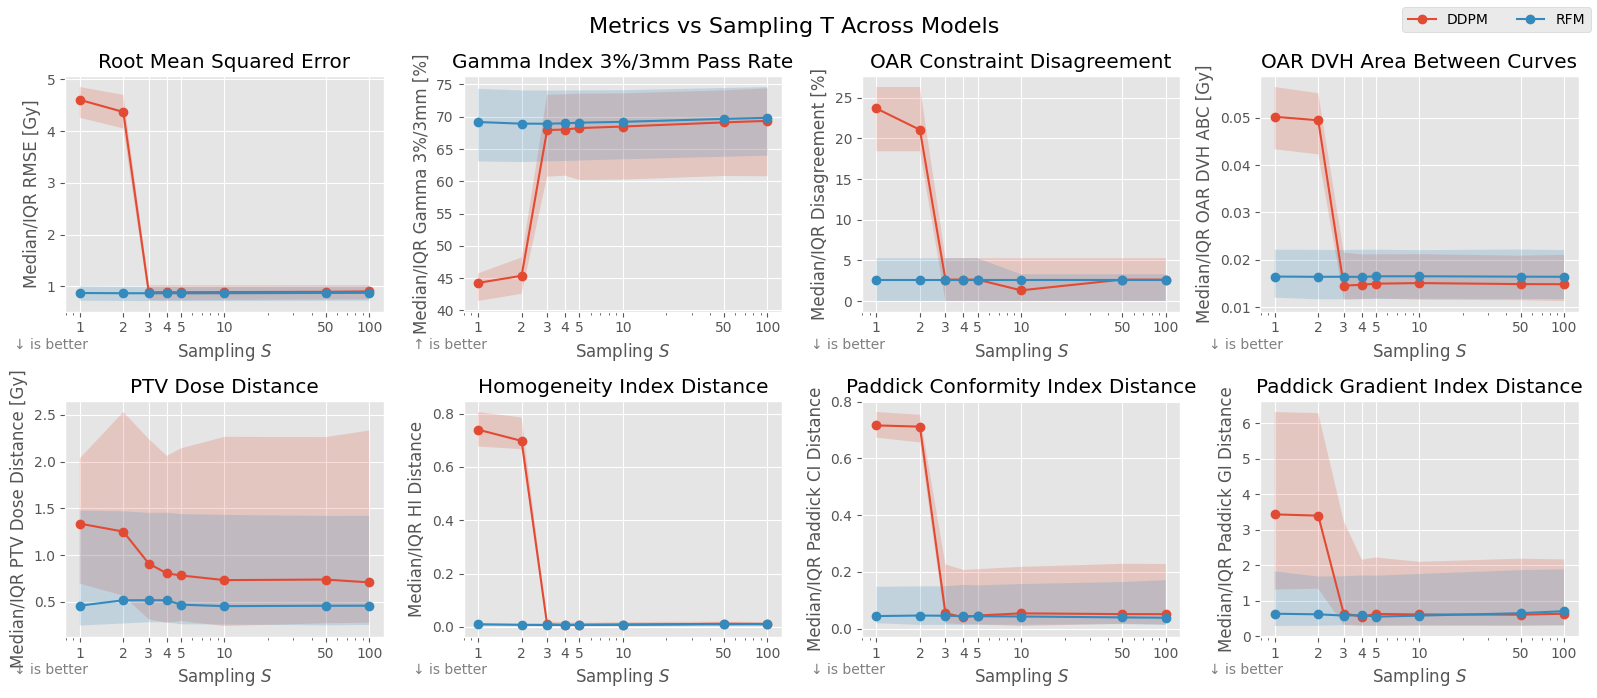

In [57]:
fig, axes = beamdiff_ddpm_flow_plan_comparison.plot_quality_over_T(METRICS_PLAN_EXTENDED, agg='median', xscale='log')
